# PPI-Caliper manuscript walkthrough

Sections 2–3 show how to select protein pairs at a target FDR. Section 4 runs the benchmark and saves the result tables. Sections 5.1 and 5.2 use those tables to draw the within-species and across-species figures, respectively.

For your own scores, start with the [Quick Start](../README.md#quick-start).

## 0. Set up

The benchmark uses 100 random splits for PLM-Interact and 30 for MINT. The tables are written under `results/tutorial/paper/`. After one run, set `RERUN_EXPERIMENTS = False` to redraw the figures from those CSVs. You can rerun any figure cell after changing the plotting code or its inputs.

In [1]:
from pathlib import Path
import sys

REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src/PPICaliper.py").is_file()),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError("Start Jupyter inside the PPI-Caliper repository.")

DATA_DIR = REPO_ROOT / "data"
AUTO_DOWNLOAD = not (DATA_DIR / "scores").is_dir()
RERUN_EXPERIMENTS = True

SEEDS = {"plm-interact": 100, "mint": 30}
RUN_ROOT = REPO_ROOT / "results/tutorial/paper"
RUN_ROOT.mkdir(parents=True, exist_ok=True)
print(f"PLM-Interact seeds: {SEEDS['plm-interact']}; MINT seeds: {SEEDS['mint']}")
print(f"Outputs: {RUN_ROOT.relative_to(REPO_ROOT)}")

PLM-Interact seeds: 100; MINT seeds: 30
Outputs: results/tutorial/paper


### Load the tools

Import PPI-Caliper and the plotting functions for both experiments. Jupyter displays the Matplotlib figure returned by each plotting call.

In [2]:
%matplotlib inline
import subprocess
import pandas as pd
from IPython.display import display

TUTORIALS_DIR = REPO_ROOT / "tutorials"
for directory in (TUTORIALS_DIR, REPO_ROOT):
    sys.path.insert(0, str(directory))

from src.PPICaliper import PPICaliper
from utils.sampling import stratified_half_split
from utils.inputs import prediction_path
from within_species.plot import plot_within_figure
from transfer_species.plot import plot_transfer_figure, plot_transfer_panel

LOG_ROOT = RUN_ROOT / "logs"
LOG_ROOT.mkdir(exist_ok=True)


def run_script(script, *arguments):
    log = LOG_ROOT / f"{Path(script).stem}-{len(list(LOG_ROOT.glob('*.log'))):03d}.log"
    command = [sys.executable, str(REPO_ROOT / script), *map(str, arguments)]
    with log.open("w") as stream:
        result = subprocess.run(command, cwd=REPO_ROOT, stdout=stream, stderr=subprocess.STDOUT)
    if result.returncode:
        raise RuntimeError(f"{script} failed. See {log}\n{log.read_text()[-2000:]}")
    print(f"Completed {script}")

## 1. Load scores

On a fresh checkout the next cell downloads the [pinned score release](https://huggingface.co/datasets/lidehan/PPI-Caliper-predictions); access requires an authorized Hugging Face account. If the scores are already present it uses the local copy. Set `AUTO_DOWNLOAD = True` to refresh an incomplete download. Preprocessing checks the score tables.

You only need original protein sequences for the optional scoring and training steps at the end.

In [3]:
if AUTO_DOWNLOAD:
    run_script("data/download_data.py", "--destination", DATA_DIR)
run_script("data/preprocess_data.py", "--data-dir", DATA_DIR)

Completed data/preprocess_data.py


### Inspect the inputs

Each row is a protein pair: `p_ab` is its prediction score and `label` is 0 or 1. Higher scores indicate stronger evidence for interaction.

In [4]:
MODELS = ("humanv11", "humanv12")
Q_LEVELS = [0.1, 0.2, 0.3]

display(pd.read_csv(prediction_path("humanv11", "ecoli", data_root=DATA_DIR),
                    usecols=["p_ab", "label"])[["p_ab", "label"]].head())

,p_ab,label
0,0.999904,1
1,0.999887,1
2,0.999877,1
3,0.999868,1
4,0.999490,1


## 2. Same-species example

Use E. coli scores from PLM-Interact humanV11. Split the pairs into calibration and test halves, preserving the label proportions. PPI-Caliper converts scores to quantiles using the calibration score distribution, then applies that same mapping to the test scores.

In [5]:
demo = pd.read_csv(prediction_path("humanv11", "ecoli", data_root=DATA_DIR), float_precision="round_trip")
calibration_idx, test_idx = stratified_half_split(demo.label.to_numpy(), seed=0, species_index=0)
calibration = demo.iloc[calibration_idx]
test = demo.iloc[test_idx]

PPI-Caliper draws ten **bootstrap calibration batches**: random samples from the **labeled calibration half**, allowing repeats. Each sampled pair keeps its score and label. Each batch contains 10% of the full dataset's pairs.

For each candidate threshold, it calculates the false-discovery proportion (FDP) in each batch, then averages across batches. With the default settings, it chooses the lowest threshold where this average stays at or below the requested FDR at that threshold and every higher threshold.

Apply the returned score threshold to the separate test pairs, selecting those with scores at or above it. A threshold of `inf` means no pairs are selected. Recompute thresholds when using a different target file.

In [6]:
caliper = PPICaliper(seed=0, species_index=0, query_size=round(len(demo) / 10))
caliper.calibration(calibration.p_ab, calibration.label, test.p_ab)

rows = []
for q in Q_LEVELS:
    threshold = caliper.select_quantile_threshold(q)
    cutoff = caliper.find_raw_score_cutoff(threshold)
    rows.append({"target_fdr": q, "cutoff_score": cutoff})

demo_results = pd.DataFrame(rows)
demo_results.to_csv(RUN_ROOT / "single_split_demo.csv", index=False)
display(demo_results.style.format({"target_fdr": "{:.1f}", "cutoff_score": "{:.17g}"}).hide(axis="index"))

target_fdr,cutoff_score
0.1,0.99989271163940441
0.2,0.99986350536346436
0.3,0.99975556135177601


## 3. Cross-species example: mouse -> yeast

Mouse scores and labels determine the quantile threshold. A separate yeast sample supplies scores for the yeast mapping. Apply the threshold to yeast test pairs.

The benchmark labels preserve class proportions when splitting. The yeast mapping and selection steps use only scores. Cross-species performance is evaluated in Section 5.2.

The table gives the score cutoff for each requested FDR level.

In [7]:
mouse = pd.read_csv(prediction_path("humanv11", "mouse", data_root=DATA_DIR))
yeast = pd.read_csv(prediction_path("humanv11", "yeast", data_root=DATA_DIR))
source_idx, _ = stratified_half_split(mouse.label.to_numpy(), seed=0, species_index=2)
mapping_idx, target_idx = stratified_half_split(yeast.label.to_numpy(), seed=0, species_index=4)
source = mouse.iloc[source_idx]
target_mapping = yeast.iloc[mapping_idx]
target_test = yeast.iloc[target_idx]

transfer_caliper = PPICaliper(seed=0, species_index=2)
transfer_caliper.calibration(
    source.p_ab, source.label, target_test.p_ab, target_mapping_scores=target_mapping.p_ab,
)

rows = []
for q in Q_LEVELS:
    threshold = transfer_caliper.select_quantile_threshold(q)
    cutoff = transfer_caliper.find_raw_score_cutoff(threshold)
    rows.append({"target_fdr": q, "cutoff_score": cutoff})

transfer_demo = pd.DataFrame(rows)
transfer_demo.to_csv(RUN_ROOT / "cross_species_demo.csv", index=False)
display(transfer_demo.style.format({"target_fdr": "{:.1f}", "cutoff_score": "{:.17g}"}).hide(axis="index"))

target_fdr,cutoff_score
0.1,0.99673908948898315
0.2,0.56687366962432861
0.3,0.0213271602988243


## 4. Run the benchmark

The experiment scripts write one row per checkpoint, split, target FDR, and species or ordered species pair. The transfer experiment also measures AUPRC from the original prediction scores. Run the scripts once to generate the tables used by the following figures.

In [8]:
if RERUN_EXPERIMENTS:
    for predictor, n_seeds in SEEDS.items():
        for experiment, folder in [("within_species", "within"), ("transfer_species", "transfer")]:
            run_script(f"tutorials/{experiment}/run_experiments.py",
                       "--predictor", predictor, "--data-root", DATA_DIR, "--n-seeds", n_seeds,
                       "--output-dir", RUN_ROOT / predictor / folder, "--no-plots")

def load_results(predictor):
    folder = RUN_ROOT / predictor
    within = pd.read_csv(folder / "within/method1_all_seed_results.csv")
    transfer = pd.read_csv(folder / "transfer/all_seed_results.csv")
    auprc = pd.read_csv(folder / "transfer/classification_metrics.csv")
    return within, transfer, auprc

plm_within, plm_transfer, plm_auprc = load_results("plm-interact")
mint_within, mint_transfer, mint_auprc = load_results("mint")

Completed tutorials/within_species/run_experiments.py


Completed tutorials/transfer_species/run_experiments.py


Completed tutorials/within_species/run_experiments.py


Completed tutorials/transfer_species/run_experiments.py


## 5. Reproducing the paper results

### 5.1 Within species

Each column is a species. Across target FDRs of 0.1 to 0.9, the three rows show empirical FDR (mean held-out FDP across splits), power (fraction of true interactions recovered), and accuracy (fraction of all test pairs classified correctly). The dashed line marks the requested FDR. The pointwise 95% intervals use Student’s *t* for empirical FDR and 1.96 times the standard error for power and accuracy. [Within-species plotting code](within_species/plot.py)

#### PLM-Interact humanV11 (Figure 2)

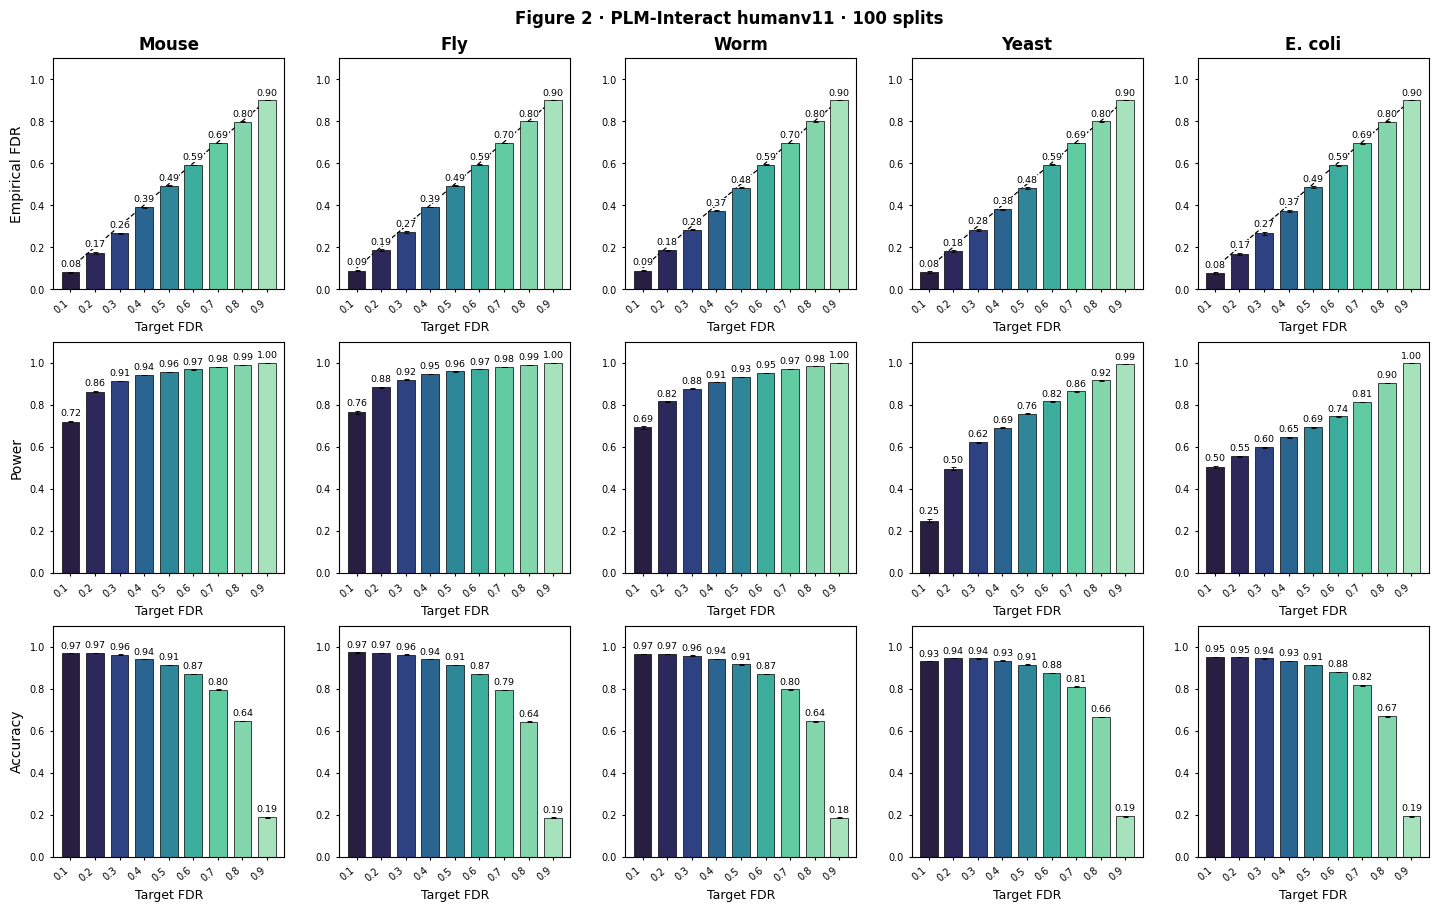

In [10]:
plot_within_figure(plm_within, "plm-interact", "humanv11");

#### PLM-Interact humanV12 (Figure A1)

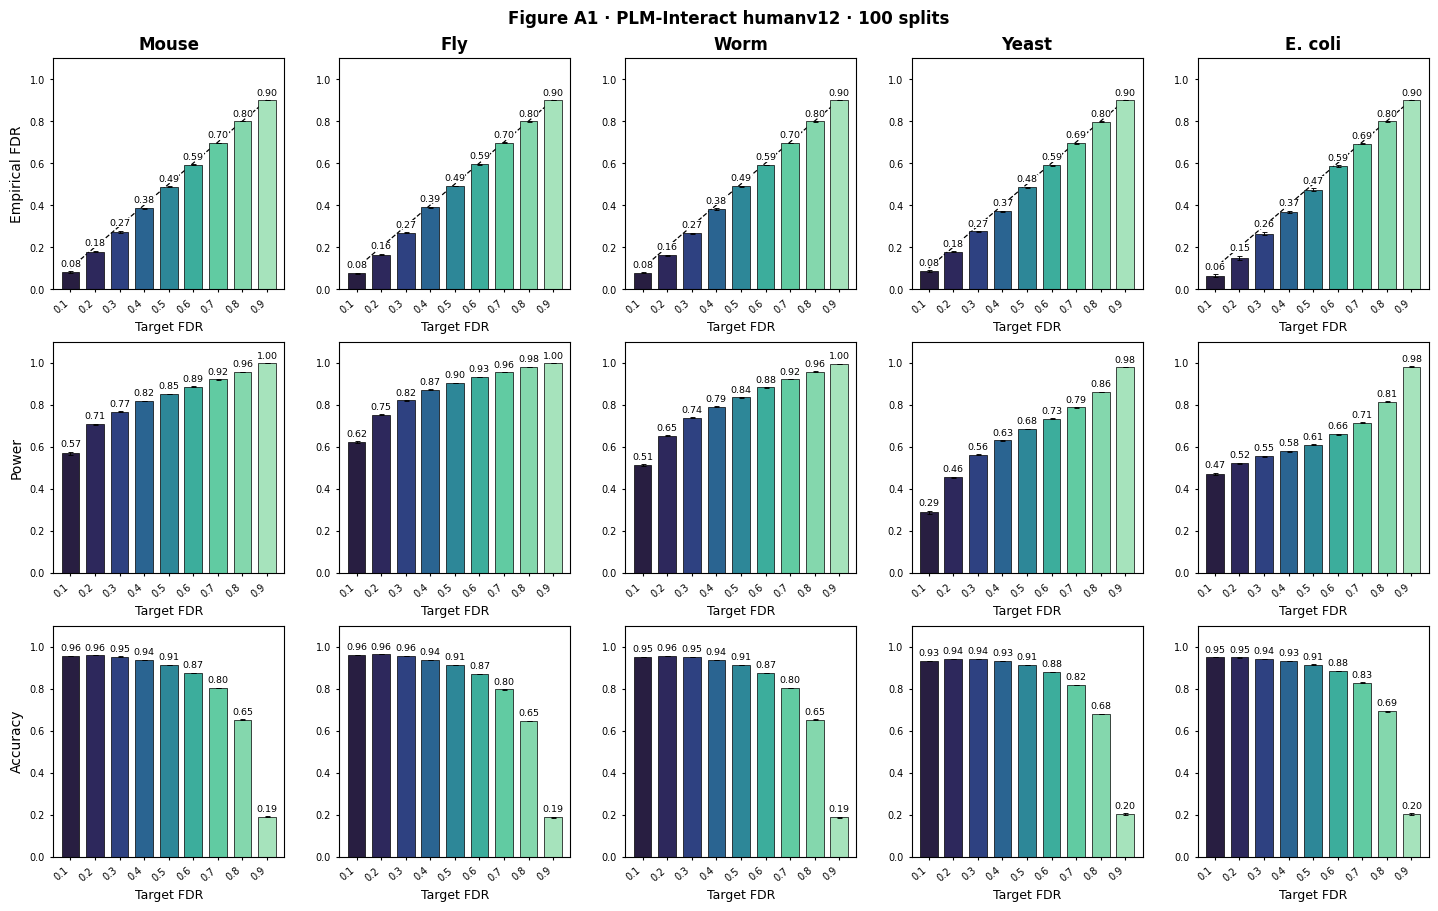

In [11]:
plot_within_figure(plm_within, "plm-interact", "humanv12");

#### MINT humanV11 (Figure A2)

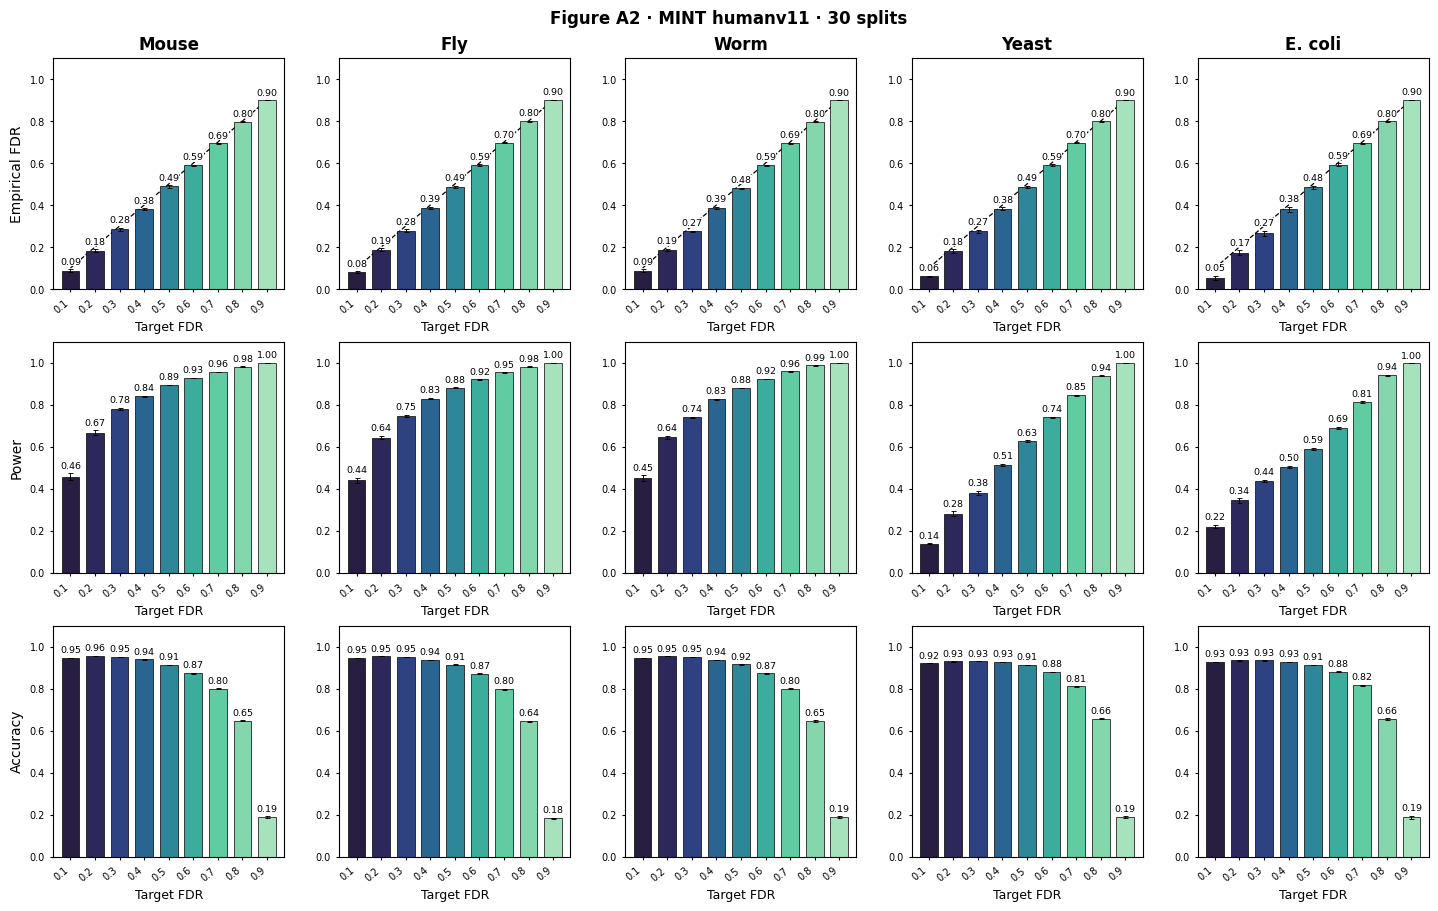

In [12]:
plot_within_figure(mint_within, "mint", "humanv11");

#### MINT humanV12 (Figure A3)

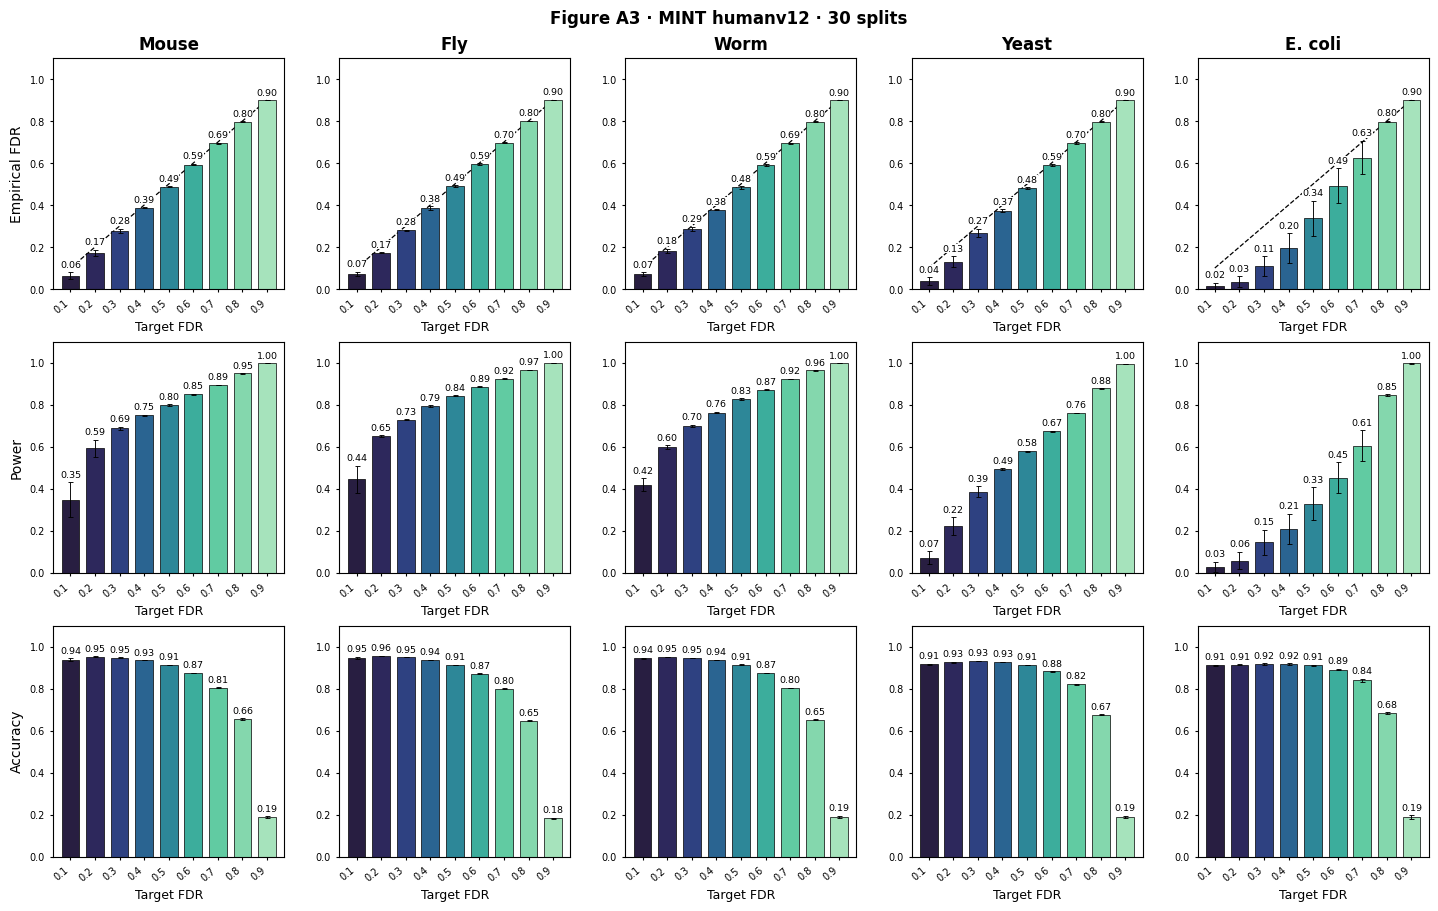

In [13]:
plot_within_figure(mint_within, "mint", "humanv12");

### 5.2 Across species

Rows show the calibration species and columns show the test species. Each bar is the mean FDP on the held-out test pairs, with a 95% Student’s *t* interval. The diagonal uses within-species results from the same checkpoint. Each tree tip gives the AUPRC of the original scores for that species.

The example below calibrates on worm and tests on E. coli. Swap the two species to draw the reverse direction. [Transfer plotting code](transfer_species/plot.py)

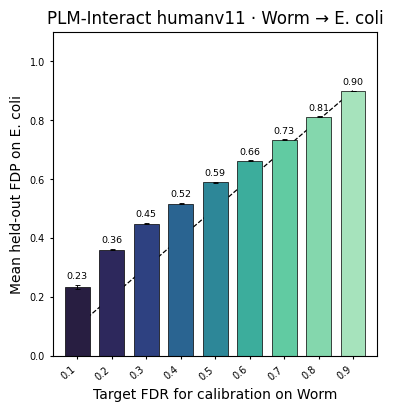

In [14]:
plot_transfer_panel(plm_transfer, plm_within, "plm-interact", "humanv11", "worm", "ecoli");

#### PLM-Interact humanV11 (Figure 3)

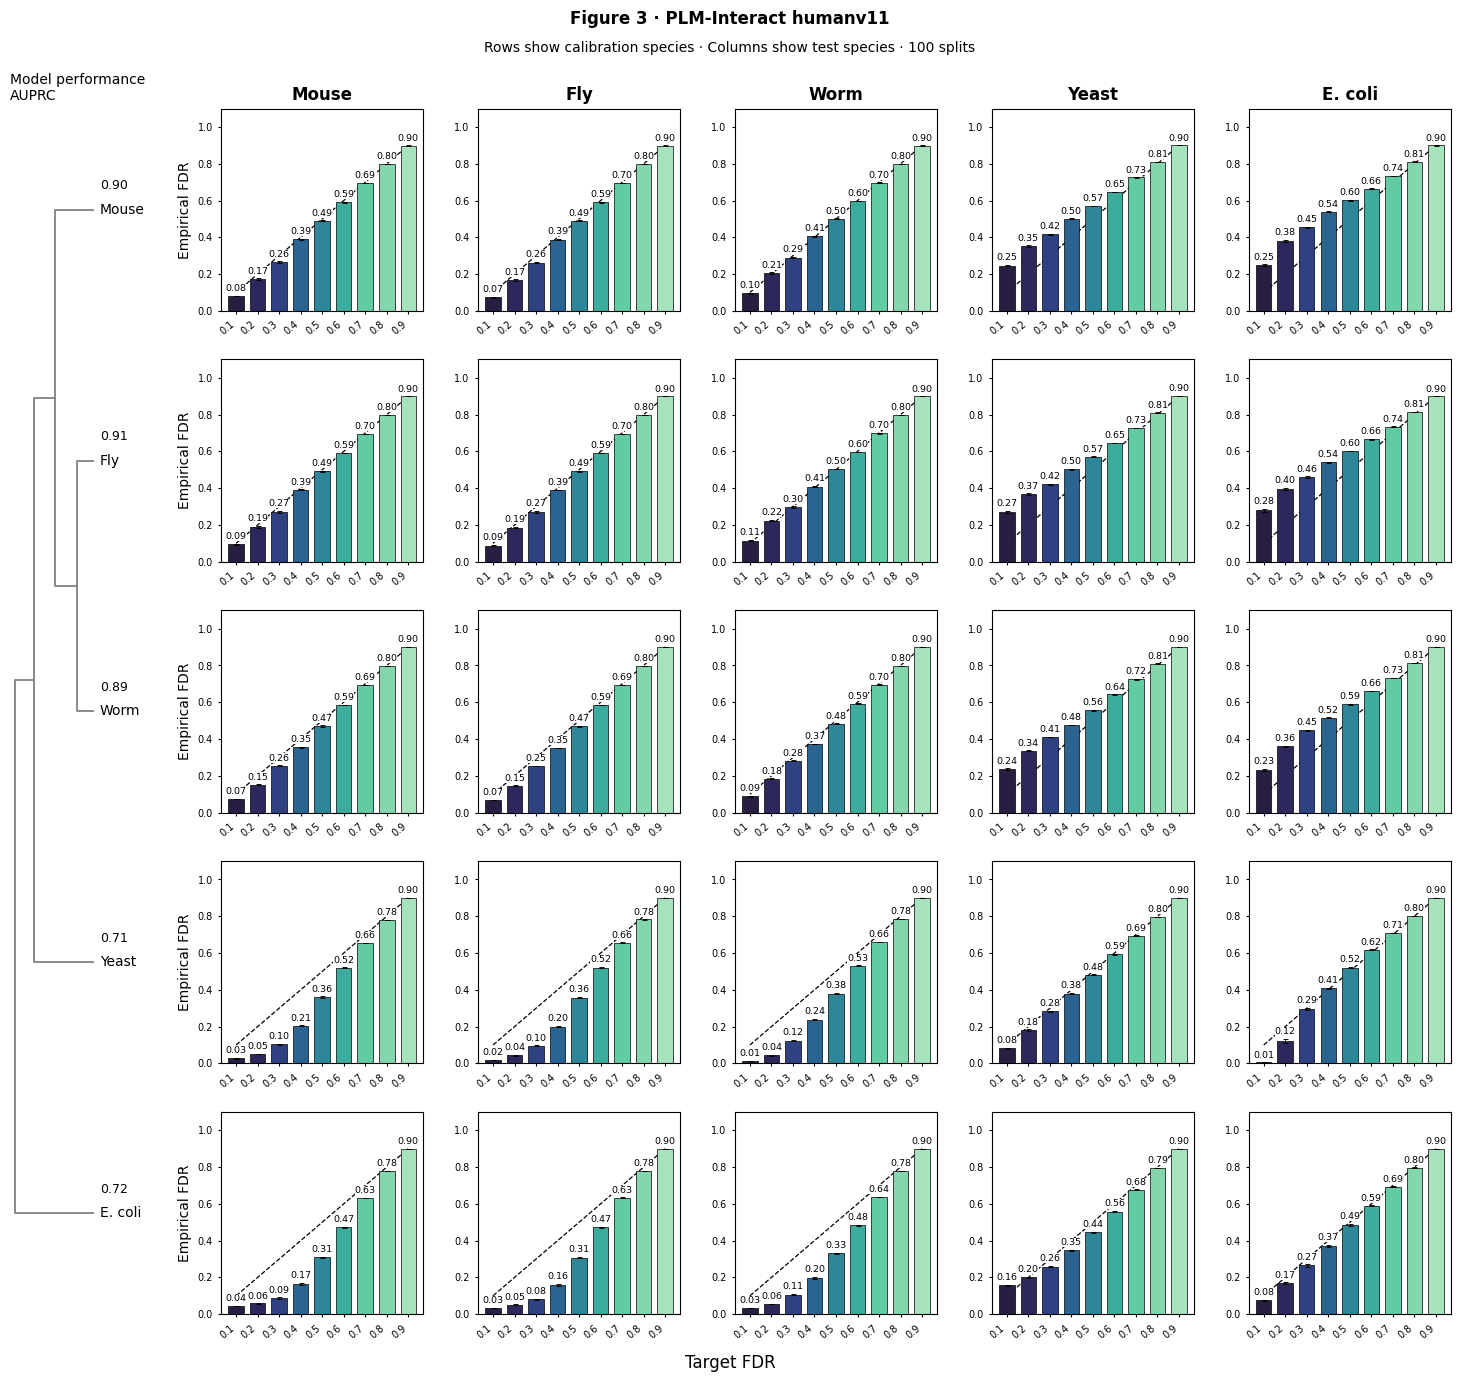

In [15]:
plot_transfer_figure(plm_transfer, plm_within, plm_auprc, "plm-interact", "humanv11");

#### PLM-Interact humanV12 (Figure A4)

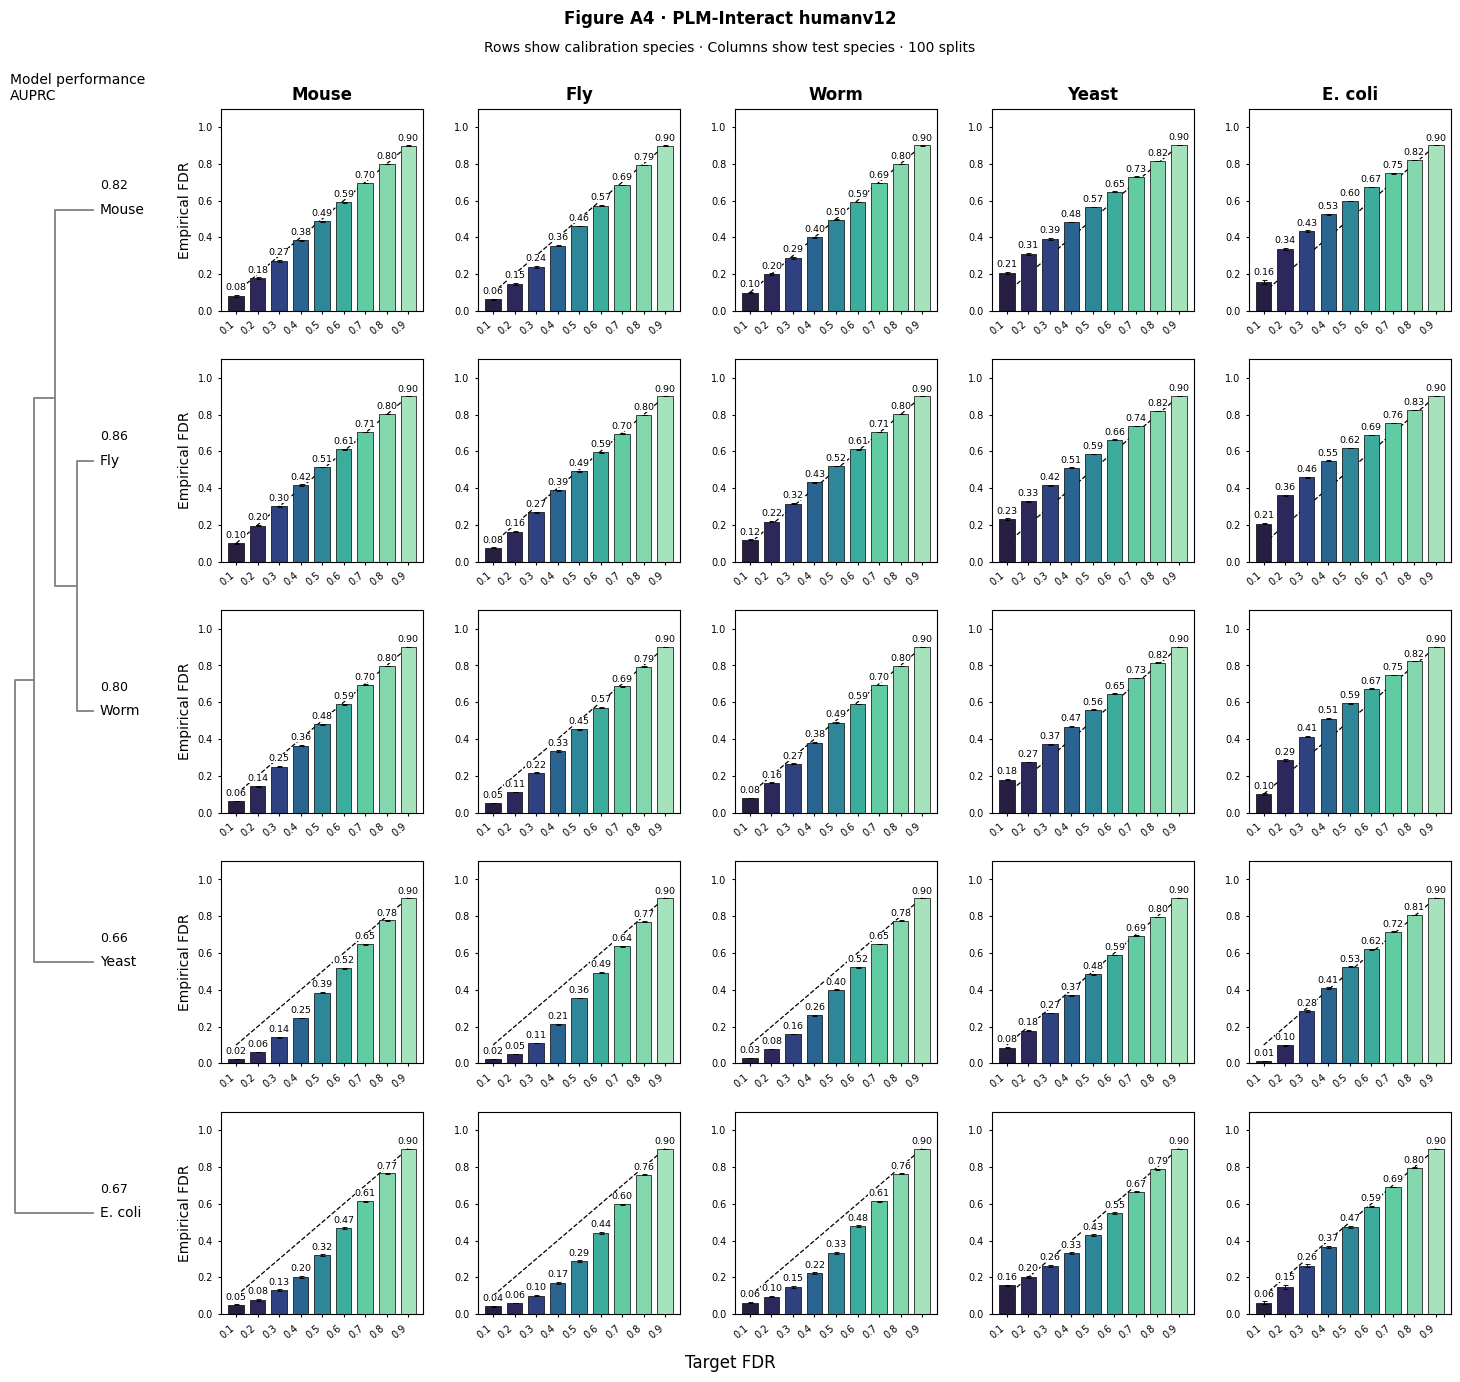

In [16]:
plot_transfer_figure(plm_transfer, plm_within, plm_auprc, "plm-interact", "humanv12");

#### MINT humanV11 (Figure A5)

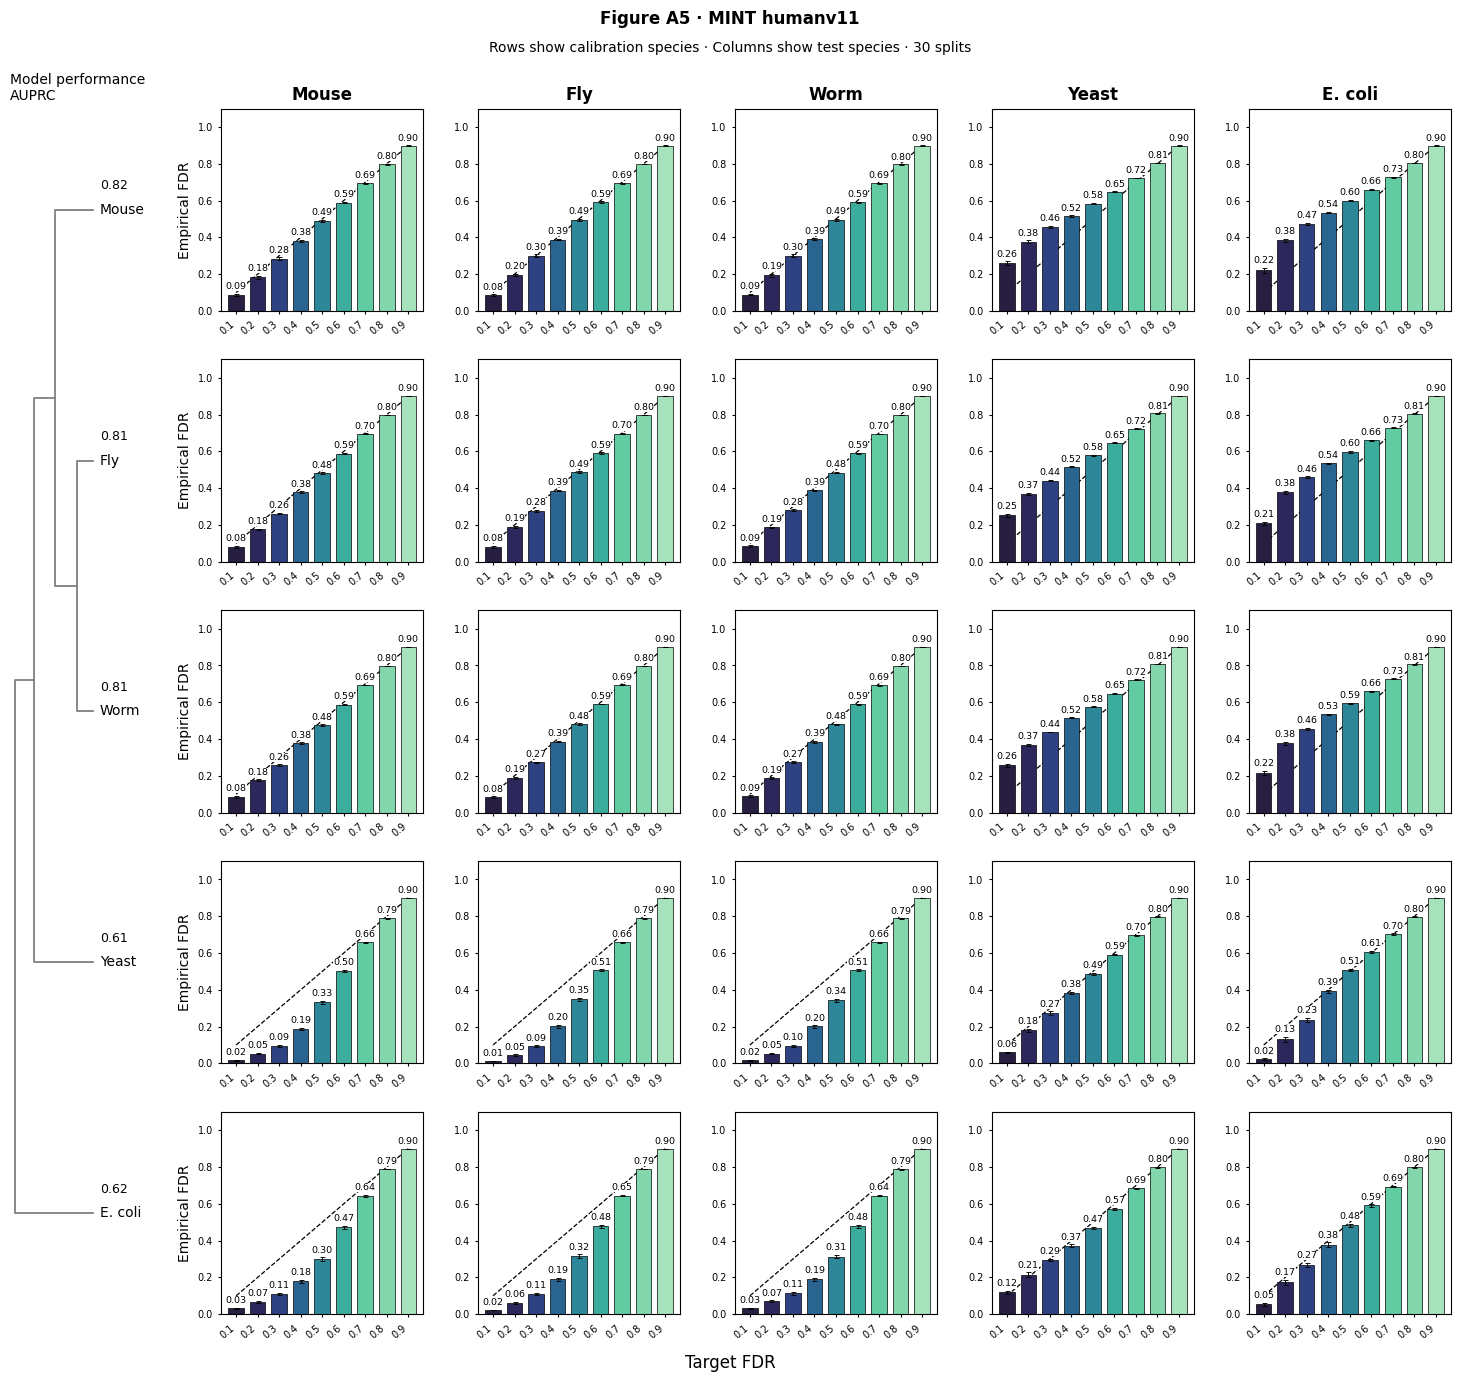

In [17]:
plot_transfer_figure(mint_transfer, mint_within, mint_auprc, "mint", "humanv11");

#### MINT humanV12 (Figure A6)

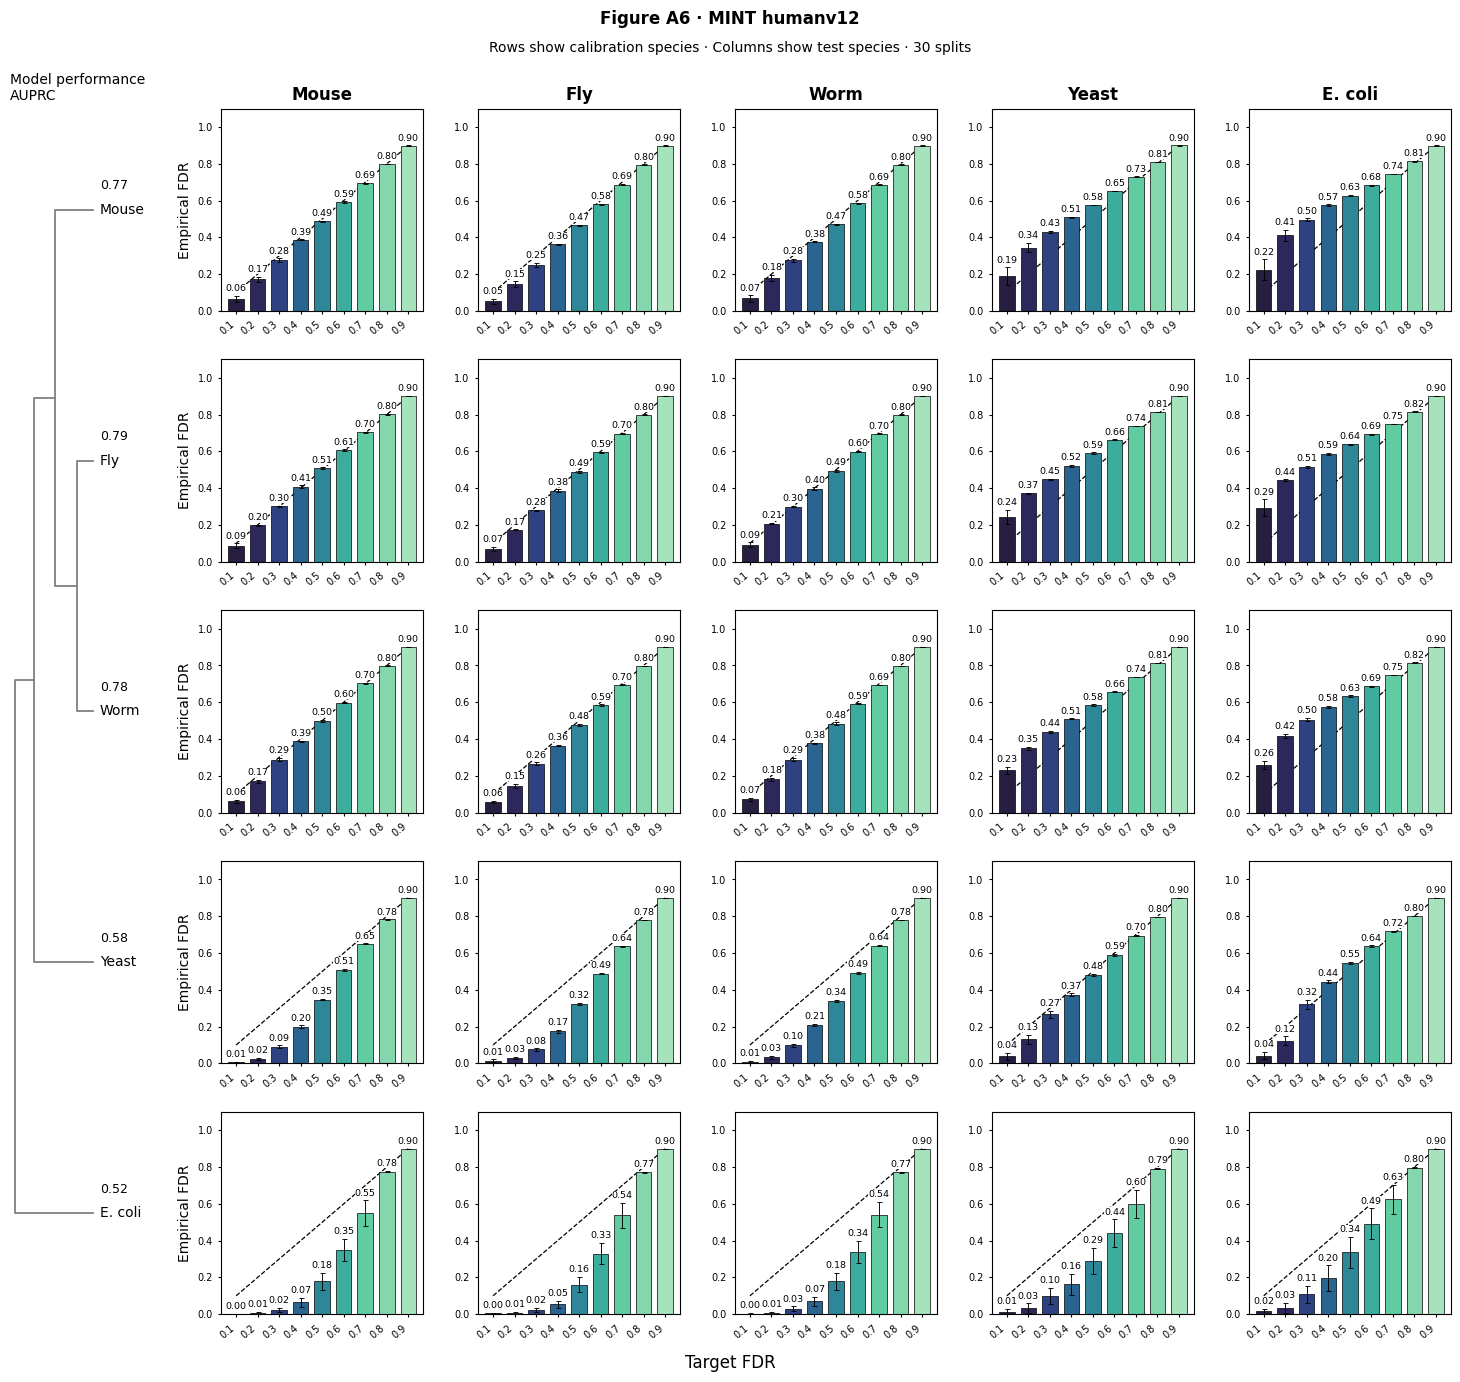

In [18]:
plot_transfer_figure(mint_transfer, mint_within, mint_auprc, "mint", "humanv12");

## 7. Optional: generate prediction scores

Generate scores from the original benchmark sequences. Set either option below to `True` to run that workflow.

In [19]:
RUN_PLM_INFERENCE = False
RUN_MINT_TRAINING = False
GPU_DEVICE = "cuda:0"

if RUN_PLM_INFERENCE or RUN_MINT_TRAINING:
    if AUTO_DOWNLOAD or not (DATA_DIR / "raw").is_dir():
        run_script("data/download_data.py", "--only-upstream", "--destination", DATA_DIR)
    run_script("data/preprocess_data.py", "--only-upstream", "--data-dir", DATA_DIR)

### PLM-Interact

Score the five species with the released humanV11 and humanV12 checkpoints. No fine-tuning is needed. See the [PLM-Interact scoring guide](computing_scores/plm_interact/README.md) for setup and options. Scores go to `results/plm-interact/scores/<model>/`.

In [20]:
if RUN_PLM_INFERENCE:
    run_script("tutorials/computing_scores/plm_interact/download_models.py")
    for model in MODELS:
        run_script("tutorials/computing_scores/plm_interact/score.py",
                   "--model", model, "--data-root", DATA_DIR / "raw", "--device", GPU_DEVICE)

### MINT

Follow the [MINT setup and training guide](computing_scores/mint/README.md) to install the official MINT code and download its encoder checkpoint. For each version, extract embeddings, train the prediction head, and score the five species. The encoder stays frozen. Scores go to `results/mint/scores/<version>/`.

In [21]:
if RUN_MINT_TRAINING:
    for version in ("v11", "v12"):
        run_script("tutorials/computing_scores/mint/extract_embeddings.py",
                   "--version", version, "--device", GPU_DEVICE)
        run_script("tutorials/computing_scores/mint/train.py",
                   "--version", version, "--device", GPU_DEVICE)
        run_script("tutorials/computing_scores/mint/score.py",
                   "--version", version, "--device", GPU_DEVICE)